In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [9]:
glass_dataset = pd.read_csv('glass.csv', header=None)

glass_dataset.columns = ['Id', 'RI', 'Na', 'Mg', 'Al', 'Si',
                         'K', 'Ca', 'Ba', 'Fe', 'Glass_type']

glass_dataset = glass_dataset.drop('Id', axis=1)

glass_dataset.head()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Glass_type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


In [10]:
features = ['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe']

x = glass_dataset.loc[:, features].values
y = glass_dataset.loc[:, ['Glass_type']].values

print(x.shape)
print(y.shape)

(214, 9)
(214, 1)


In [11]:
x = StandardScaler().fit_transform(x)

pd.DataFrame(data=x, columns=features).head()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
0,0.872868,0.284953,1.254639,-0.692442,-1.127082,-0.671705,-0.145766,-0.352877,-0.586451
1,-0.249333,0.591817,0.636168,-0.170460,0.102319,-0.026213,-0.793734,-0.352877,-0.586451
2,-0.721318,0.149933,0.601422,0.190912,0.438787,-0.164533,-0.828949,-0.352877,-0.586451
3,-0.232831,-0.242853,0.698710,-0.310994,-0.052974,0.112107,-0.519052,-0.352877,-0.586451
4,-0.312045,-0.169205,0.650066,-0.411375,0.555256,0.081369,-0.624699,-0.352877,-0.586451


In [12]:
pca = PCA(n_components=2)

principalComponents = pca.fit_transform(x)

principalDf = pd.DataFrame(
    data=principalComponents,
    columns=['principal component 1', 'principal component 2']
)

principalDf.head()

,principal component 1,principal component 2
0,1.151140,0.529488
1,-0.574137,0.759788
2,-0.940160,0.929836
3,-0.142083,0.961677
4,-0.351092,1.091249


In [13]:
finalDf = pd.concat(
    [principalDf, glass_dataset[['Glass_type']]],
    axis=1
)

finalDf.head()

,principal component 1,principal component 2,Glass_type
0,1.151140,0.529488,1
1,-0.574137,0.759788,1
2,-0.940160,0.929836,1
3,-0.142083,0.961677,1
4,-0.351092,1.091249,1


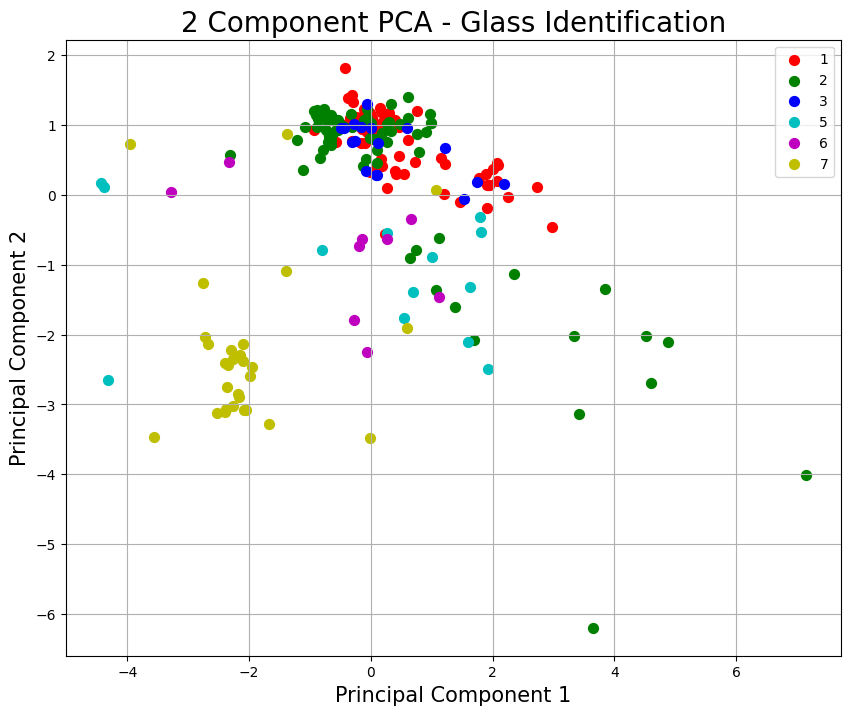

In [14]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(1, 1, 1)

ax.set_xlabel('Principal Component 1', fontsize=15)
ax.set_ylabel('Principal Component 2', fontsize=15)
ax.set_title('2 Component PCA - Glass Identification', fontsize=20)

targets = [1, 2, 3, 5, 6, 7]
colors = ['r', 'g', 'b', 'c', 'm', 'y']

for target, color in zip(targets, colors):
    indicesToKeep = finalDf['Glass_type'] == target

    ax.scatter(
        finalDf.loc[indicesToKeep, 'principal component 1'],
        finalDf.loc[indicesToKeep, 'principal component 2'],
        c=color,
        s=50
    )

ax.legend(targets)
ax.grid()

plt.show()

In [15]:
print(pca.explained_variance_ratio_)

print('PC1:', pca.explained_variance_ratio_[0])
print('PC2:', pca.explained_variance_ratio_[1])

print('Total Explained Variance:',
      sum(pca.explained_variance_ratio_))

[0.27901819 0.2277858 ]
PC1: 0.27901819179456455
PC2: 0.2277857983167042
Total Explained Variance: 0.5068039901112688



## Explanation of the Result

This dataset contains 214 glass samples and 9 features.

I used PCA to reduce 9 features to 2 principal components.

Each point represents one glass sample. Different colors represent different glass types.

Some glass types overlap because they have similar chemical properties.

PCA helps us see patterns in the data using a two-dimensional graph.
